In [ ]:
# MM811 - Programming Assignment
# Question 2


In [ ]:
# Imports and setup
# Source: PyTorch documentation https://pytorch.org/docs/stable/index.html

import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 811
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cpu':
    print('Warning: GPU unavailable. Training will be slower.')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = '/content/drive/MyDrive/M811_Assignment/Task2_Autoencoder/binary_autoencoder_subset_rewrite'
except ImportError:
    SAVE_DIR = './binary_autoencoder_subset_rewrite'
os.makedirs(SAVE_DIR, exist_ok=True)
print('Saving to:', SAVE_DIR)


Device: cuda
Mounted at /content/drive
Saving to: /content/drive/MyDrive/M811_Assignment/Task2_Autoencoder/binary_autoencoder_subset_rewrite


In [ ]:
# Load the MNIST images
# Source: GeeksforGeeks - MNIST Dataset
# https://www.geeksforgeeks.org/machine-learning/mnist-dataset/ (Accessed 10/17/26)

NUM_IMAGES = 256
assert NUM_IMAGES in (256, 1024, 60000)

mnist_train = datasets.MNIST(root='./data', train=True, download=True)
mnist_test  = datasets.MNIST(root='./data', train=False, download=True)

def normalise_images(ds):
    return ds.data.float().div(255.0).unsqueeze(1)   # N x 1 x 28 x 28 in [0, 1]

full_train_images = normalise_images(mnist_train)
selected_indices = torch.randperm(full_train_images.size(0), generator=torch.Generator().manual_seed(SEED))

train_images = full_train_images[selected_indices[:NUM_IMAGES]].to(device)
test_images  = normalise_images(mnist_test).to(device)

def get_batches(x, batch_size, shuffle=False):
    n = x.size(0)
    if shuffle:
        idx = torch.randperm(n, device=x.device)
        stop = n - n % batch_size
    else:
        idx = torch.arange(n, device=x.device)
        stop = n
    for i in range(0, stop, batch_size):
        yield x[idx[i:i + batch_size]]

print('Working subset:', tuple(train_images.shape), '| held-out test:', tuple(test_images.shape))
print('Pixel range:', train_images.min().item(), train_images.max().item())
print('Digit counts in subset:', torch.bincount(mnist_train.targets[selected_indices[:NUM_IMAGES]], minlength=10).tolist())

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 347kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.89MB/s]


Working subset: (256, 1, 28, 28) | held-out test: (10000, 1, 28, 28)
Pixel range: 0.0 1.0
Digit counts in subset: [22, 24, 29, 27, 20, 22, 21, 29, 25, 37]


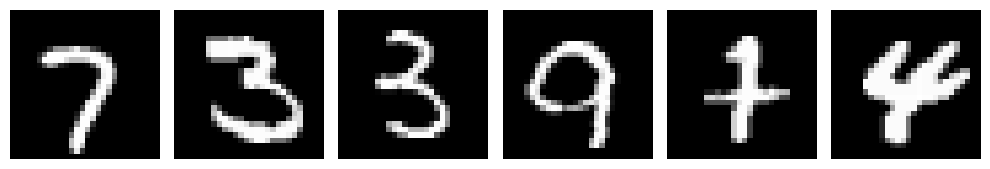

In [ ]:
# View some MNIST images before training
# Source: Matplotlib imshow
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html

fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(train_images[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# Binary straight-through estimator
# Source: Bengio, Y., Léonard, N. and Courville, A. (2013).
# Estimating or Propagating Gradients Through Stochastic Neurons for Conditional Computation.
# https://arxiv.org/abs/1308.3432

class BinarizeFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return torch.where(x >= 0, torch.ones_like(x), -torch.ones_like(x))

    @staticmethod
    def backward(ctx, grad_out):
        (x,) = ctx.saved_tensors
        return grad_out * (x.abs() <= 1).to(grad_out.dtype)

class BinarySTE(nn.Module):
    def forward(self, x):
        return BinarizeFn.apply(x)

In [ ]:
# Original architecture study was inspired by:
# Ronneberger, O., Fischer, P. and Brox, T. (2015).

def conv_block(cin, cout, stride=1):
    return [nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            *conv_block(1, 64),
            *conv_block(64, 64),
            *conv_block(64, 128, stride=2),    # 14 x 14
            *conv_block(128, 128),
            *conv_block(128, 256, stride=2),   # 7 x 7
            *conv_block(256, 256),
        )
        self.to_latent = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 512, bias=False),
            nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Linear(512, 48),
        )
        # Normalises each of the 48 logits so the sign threshold is centred.
        self.latent_norm = nn.BatchNorm1d(48)

    def forward(self, x):
        z = self.latent_norm(self.to_latent(self.features(x)))   # N x 48
        return z.view(-1, 3, 4, 4)                               # N x 3 x 4 x 4 (continuous logits)


In [ ]:
# Source: PyTorch ConvTranspose2d
# https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.from_latent = nn.Sequential(
            nn.Flatten(),
            nn.Linear(48, 512, bias=False), nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Linear(512, 256 * 7 * 7, bias=False), nn.BatchNorm1d(256 * 7 * 7), nn.ReLU(inplace=True),
        )
        self.up = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1, bias=False),  # 14 x 14
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            *conv_block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1, bias=False),   # 28 x 28
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            *conv_block(64, 64),
            nn.Conv2d(64, 1, 3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, z):
        h = self.from_latent(z).view(-1, 256, 7, 7)
        return self.up(h)


In [ ]:

class BinaryAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.binarizer = BinarySTE()
        self.decoder = Decoder()

    def forward(self, x):
        logits = self.encoder(x)
        binary_latent = self.binarizer(logits)       # exactly -1 / +1
        return self.decoder(binary_latent), binary_latent

    @torch.no_grad()
    def encode(self, x):
        self.eval()
        return self.binarizer(self.encoder(x))


In [ ]:

model = BinaryAutoencoder().to(device)

model.eval()
with torch.no_grad():
    reconstructed, binary_latent = model(train_images[:8])
print('Input:         ', tuple(train_images[:8].shape))
print('Binary latent: ', tuple(binary_latent.shape), '-> unique values', torch.unique(binary_latent).tolist())
print('Reconstruction:', tuple(reconstructed.shape))
assert binary_latent.shape == (8, 3, 4, 4)
assert torch.all((binary_latent == 1) | (binary_latent == -1))
assert reconstructed.shape == (8, 1, 28, 28)
print('Parameters: %.2f M' % (sum(p.numel() for p in model.parameters()) / 1e6))

Input:          (8, 1, 28, 28)
Binary latent:  (8, 3, 4, 4) -> unique values [-1.0, 1.0]
Reconstruction: (8, 1, 28, 28)
Parameters: 14.91 M


In [ ]:

# Source: PyTorch autograd https://docs.pytorch.org/docs/stable/autograd.html

def calculate_image_mse(recon, x):
    return ((recon - x) ** 2).mean(dim=(1, 2, 3))

def psnr_loss(recon, x, eps=1e-5):
    return torch.log(calculate_image_mse(recon, x) + eps).mean()

@torch.no_grad()
def evaluate(x_data, model, batch_size=500):
    model.eval()
    mses = []
    for xb in get_batches(x_data, batch_size):
        recon, _ = model(xb)
        mses.append(calculate_image_mse(recon, xb))
    mses = torch.cat(mses)
    psnr = 10 * torch.log10(1.0 / mses.clamp(min=1e-10))
    return mses.mean().item(), psnr.mean().item(), psnr

In [ ]:
# Source: PyTorch Adam optimizer
# https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html
# Source: PyTorch OneCycleLR scheduler
# https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.OneCycleLR.html

training_options = {256:   dict(epochs=1500, batch=64),
           1024:  dict(epochs=500,  batch=64),
           60000: dict(epochs=100,  batch=128)}
NUM_EPOCHS = training_options[NUM_IMAGES]['epochs']
BATCH_SIZE = training_options[NUM_IMAGES]['batch']
LEARNING_RATE = 2e-3
print_every = max(1, NUM_EPOCHS // 40)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
steps_per_epoch = train_images.size(0) // BATCH_SIZE
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LEARNING_RATE, epochs=NUM_EPOCHS, steps_per_epoch=steps_per_epoch,
    pct_start=0.1, anneal_strategy='cos', final_div_factor=1e3)

checkpoint_path = os.path.join(SAVE_DIR, 'binary_autoencoder_subset_rewrite_best.pth')
best_psnr = float('-inf')
history = {'train_loss': [], 'subset_mse': [], 'subset_psnr': []}   # subset statistics use training images in eval mode; NOT held-out validation

t0 = time.time()
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running, count = 0.0, 0
    for xb in get_batches(train_images, BATCH_SIZE, shuffle=True):
        recon, _ = model(xb)
        loss = psnr_loss(recon, xb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        running += loss.item() * xb.size(0); count += xb.size(0)

    subset_mse, subset_psnr, _ = evaluate(train_images, model)
    history['train_loss'].append(running / count)
    history['subset_mse'].append(subset_mse)
    history['subset_psnr'].append(subset_psnr)

    is_best = subset_psnr > best_psnr
    if is_best:
        best_psnr = subset_psnr
        torch.save({'model_state_dict': model.state_dict(),
                    'epoch': epoch, 'best_subset_psnr': best_psnr}, checkpoint_path)
    if epoch % print_every == 0 or epoch == NUM_EPOCHS:
        print(f'Epoch {epoch:4d}/{NUM_EPOCHS} | train log-MSE {running/count:7.4f} | '
              f'subset PSNR {subset_psnr:5.2f} dB | best {best_psnr:5.2f} dB | {time.time()-t0:5.0f}s')

print(f'Best subset PSNR: {best_psnr:.2f} dB')

Epoch   37/1500 | train log-MSE -4.6481 | subset PSNR 19.63 dB | best 19.86 dB |    19s
Epoch   74/1500 | train log-MSE -5.8027 | subset PSNR 25.71 dB | best 25.84 dB |    30s
Epoch  111/1500 | train log-MSE -6.7607 | subset PSNR 30.04 dB | best 30.13 dB |    40s
Epoch  148/1500 | train log-MSE -7.6099 | subset PSNR 34.30 dB | best 34.30 dB |    49s
Epoch  185/1500 | train log-MSE -8.0931 | subset PSNR 34.50 dB | best 37.23 dB |    57s
Epoch  222/1500 | train log-MSE -8.8512 | subset PSNR 40.12 dB | best 40.24 dB |    66s
Epoch  259/1500 | train log-MSE -9.0088 | subset PSNR 41.08 dB | best 42.07 dB |    75s
Epoch  296/1500 | train log-MSE -9.5124 | subset PSNR 42.80 dB | best 43.00 dB |    83s
Epoch  333/1500 | train log-MSE -9.8152 | subset PSNR 45.06 dB | best 45.12 dB |    91s
Epoch  370/1500 | train log-MSE -10.0888 | subset PSNR 46.62 dB | best 46.62 dB |   100s
Epoch  407/1500 | train log-MSE -10.0455 | subset PSNR 45.41 dB | best 47.27 dB |   108s
Epoch  444/1500 | train log-MS

In [ ]:

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])

subset_mse, subset_psnr, individual_psnrs = evaluate(train_images, model)
test_mse, test_psnr, _ = evaluate(test_images, model)

print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f'AVERAGE PSNR on the {NUM_IMAGES}-image working set: {subset_psnr:.2f} dB   (MSE {subset_mse:.6f})')
print(f'  worst image / 10th percentile / median: {individual_psnrs.min().item():.2f} / '
      f'{torch.quantile(individual_psnrs, 0.10).item():.2f} / {individual_psnrs.median().item():.2f} dB')
print('  > 25 dB:', subset_psnr > 25)
print(f'Held-out official test set (10,000 unseen images): {test_psnr:.2f} dB   (separate held-out evaluation)')

Best checkpoint epoch: 1483
AVERAGE PSNR on the 256-image working set: 66.11 dB   (MSE 0.000001)
  worst image / 10th percentile / median: 38.16 / 64.36 / 66.22 dB
  > 25 dB: True
Held-out official test set (10,000 unseen images): 14.50 dB   (separate held-out evaluation)


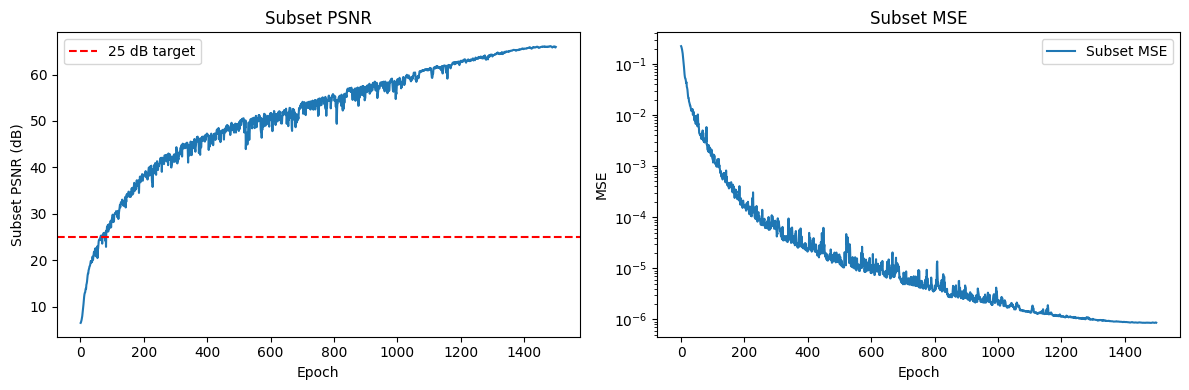

In [ ]:
# Plot PSNR and MSE during training
# Source: Matplotlib plotting documentation https://matplotlib.org/stable/

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(history['subset_psnr']) + 1), history['subset_psnr'])
axes[0].axhline(25, linestyle='--', color='r', label='25 dB target')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Subset PSNR (dB)')
axes[0].set_title('Subset PSNR'); axes[0].legend()

axes[1].plot(history['subset_mse'], label='Subset MSE')
axes[1].set_yscale('log')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MSE'); axes[1].set_title('Subset MSE')
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150)
plt.show()

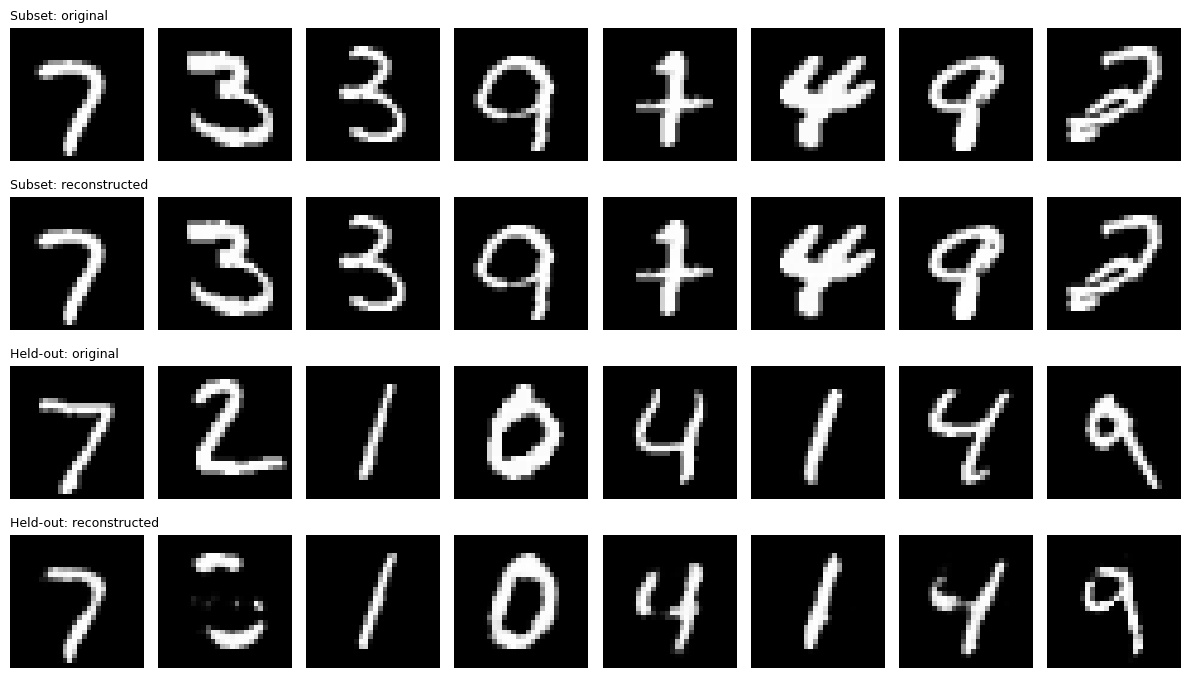

Example binary latent (image 0), shape (3, 4, 4)
[[[-1 -1  1 -1]
  [ 1  1 -1 -1]
  [-1  1  1  1]
  [ 1 -1  1 -1]]

 [[ 1  1 -1 -1]
  [ 1 -1  1 -1]
  [-1  1  1  1]
  [ 1  1  1 -1]]

 [[-1  1 -1  1]
  [ 1 -1  1 -1]
  [ 1 -1  1 -1]
  [ 1  1 -1 -1]]]


In [ ]:
# Compare original and reconstructed MNIST images
# Source: Matplotlib imshow
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html

model.eval()
with torch.no_grad():
    subset_reconstructions, z = model(train_images[:8])
    test_reconstructions, _ = model(test_images[:8])

fig, axes = plt.subplots(4, 8, figsize=(12, 7))
rows = [(train_images[:8], 'Subset: original'), (subset_reconstructions, 'Subset: reconstructed'),
        (test_images[:8], 'Held-out: original'), (test_reconstructions, 'Held-out: reconstructed')]
for r, (imgs, title) in enumerate(rows):
    for i in range(8):
        axes[r, i].imshow(imgs[i, 0].cpu(), cmap='gray', vmin=0, vmax=1); axes[r, i].axis('off')
    axes[r, 0].set_title(title, loc='left', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'reconstructions.png'), dpi=150)
plt.show()

print('Example binary latent (image 0), shape', tuple(z[0].shape))
print(z[0].int().cpu().numpy())

In [ ]:

model.eval()
codes = []
with torch.no_grad():
    for xb in get_batches(train_images, 500):
        codes.append(model.encode(xb).flatten(start_dim=1).cpu())
codes = torch.cat(codes)                                  # NUM_IMAGES x 48

positive_fraction = (codes == 1).float().mean(dim=0)
active_bits = ((positive_fraction > 0.01) & (positive_fraction < 0.99)).sum().item()

print('Latent per batch: N x 3 x 4 x 4; flattened codes:', tuple(codes.shape))
print('Unique latent values:', torch.unique(codes).tolist())
print('Non-binary entries:', ((codes != -1) & (codes != 1)).sum().item())
print(f'Unique 48-bit codes: {torch.unique(codes, dim=0).shape[0]} / {codes.shape[0]}')
print('Bits used (1%-99% positive):', active_bits, '/ 48')
assert torch.all((codes == -1) | (codes == 1))

Latent per batch: N x 3 x 4 x 4; flattened codes: (256, 48)
Unique latent values: [-1.0, 1.0]
Non-binary entries: 0
Unique 48-bit codes: 256 / 256
Bits used (1%-99% positive): 48 / 48
